Practical: Decision Tree and Random Forest on Heart Disease Dataset




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [2]:
# UCI Cleveland Heart Disease dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Dataset column names
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'target'
]

# Load dataset
df = pd.read_csv(
    url,
    names=columns,
    na_values='?'
)

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

First Five Rows:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Dataset Shape:
(303, 14)

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [3]:
# Convert all columns into numeric format
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Convert target into binary classification
# 0 = No Heart Disease
# 1, 2, 3, 4 = Heart Disease

df['target'] = (df['target'] > 0).astype(int)

print("Target Distribution:")
print(df['target'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Target Distribution:
target
0    164
1    139
Name: count, dtype: int64

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [4]:
X = df.drop('target', axis=1)

y = df['target']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  
0    3.0  0.0   6.0  
1    2.0  3.0   3.0  
2    2.0  2.0   7.0  
3    3.0  0.0   3.0  
4    1.0  0.0   3.0  

Target Values:
0    0
1    1
2    1
3    0
4    0
Name: target, dtype: int64


In [5]:
numeric_features = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

print("Numerical Features:", numeric_features)

print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [6]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (242, 13)
Testing Data: (61, 13)


In [8]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

# Train model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [9]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=4,
        random_state=42
    ))
])

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [10]:
# Decision Tree predictions
dt_pred = dt_model.predict(X_test)

# Random Forest predictions
rf_pred = rf_model.predict(X_test)

print("Decision Tree Predictions:")
print(dt_pred[:10])

print("\nRandom Forest Predictions:")
print(rf_pred[:10])

Decision Tree Predictions:
[0 1 0 0 0 0 1 0 1 0]

Random Forest Predictions:
[0 1 0 0 0 0 0 0 1 0]


In [11]:
dt_accuracy = accuracy_score(y_test, dt_pred)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Decision Tree Accuracy: 78.68852459016394 %
Random Forest Accuracy: 83.60655737704919 %


Decision Tree Confusion Matrix:
[[25  8]
 [ 5 23]]


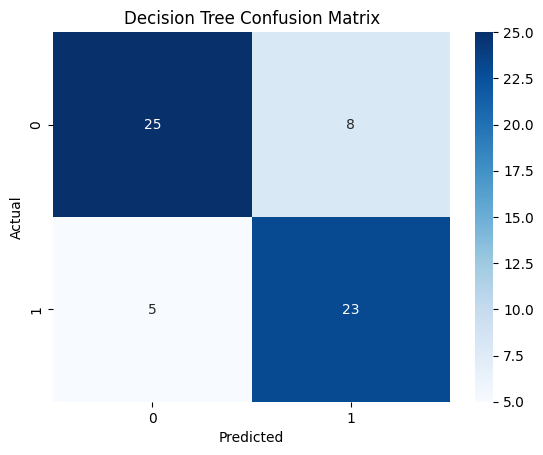

In [12]:
dt_cm = confusion_matrix(y_test, dt_pred)

print("Decision Tree Confusion Matrix:")
print(dt_cm)

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

Random Forest Confusion Matrix:
[[28  5]
 [ 5 23]]


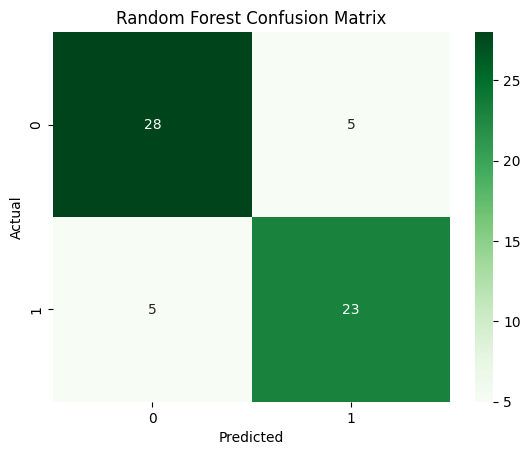

In [13]:
rf_cm = confusion_matrix(y_test, rf_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [14]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, dt_pred))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.76      0.79        33
           1       0.74      0.82      0.78        28

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        33
           1       0.82      0.82      0.82        28

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



In [15]:
depths = [1, 2, 3, 4, 5, 6, 8, None]

train_scores = []
test_scores = []

for depth in depths:

    temp_model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    temp_model.fit(X_train, y_train)

    train_scores.append(
        temp_model.score(X_train, y_train)
    )

    test_scores.append(
        temp_model.score(X_test, y_test)
    )

print("Depth | Training Accuracy | Testing Accuracy")

for depth, train_acc, test_acc in zip(
    depths, train_scores, test_scores
):
    print(depth, "|", round(train_acc, 3), "|", round(test_acc, 3))

Depth | Training Accuracy | Testing Accuracy
1 | 0.773 | 0.721
2 | 0.773 | 0.77
3 | 0.843 | 0.869
4 | 0.88 | 0.787
5 | 0.926 | 0.754
6 | 0.963 | 0.836
8 | 0.996 | 0.787
None | 1.0 | 0.738


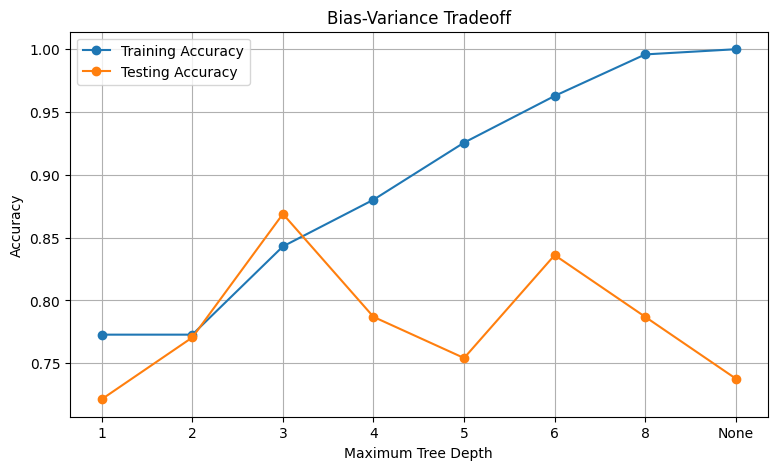

In [16]:
plt.figure(figsize=(9, 5))

depth_labels = [str(d) for d in depths]

plt.plot(
    depth_labels,
    train_scores,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depth_labels,
    test_scores,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")

plt.title("Bias-Variance Tradeoff")

plt.legend()
plt.grid()
plt.show()

In [17]:
# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Get Random Forest feature importance
importance_values = rf_model.named_steps[
    'classifier'
].feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

# Sort by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(importance_df)

Feature Importance:
             Feature  Importance
25     cat__thal_3.0    0.137063
27     cat__thal_7.0    0.109420
10       cat__cp_4.0    0.099836
21       cat__ca_0.0    0.099377
3       num__thalach    0.079510
4       num__oldpeak    0.056588
16    cat__exang_0.0    0.054138
17    cat__exang_1.0    0.047211
2          num__chol    0.042069
19    cat__slope_2.0    0.036527
1      num__trestbps    0.035688
18    cat__slope_1.0    0.034631
0           num__age    0.034356
5       cat__sex_0.0    0.024459
6       cat__sex_1.0    0.022037
7        cat__cp_1.0    0.012362
9        cat__cp_3.0    0.011985
22       cat__ca_1.0    0.011915
23       cat__ca_2.0    0.010197
8        cat__cp_2.0    0.008968
13  cat__restecg_0.0    0.008042
24       cat__ca_3.0    0.007527
15  cat__restecg_2.0    0.005455
12      cat__fbs_1.0    0.002957
20    cat__slope_3.0    0.002668
26     cat__thal_6.0    0.002657
11      cat__fbs_0.0    0.002356
14  cat__restecg_1.0    0.000000


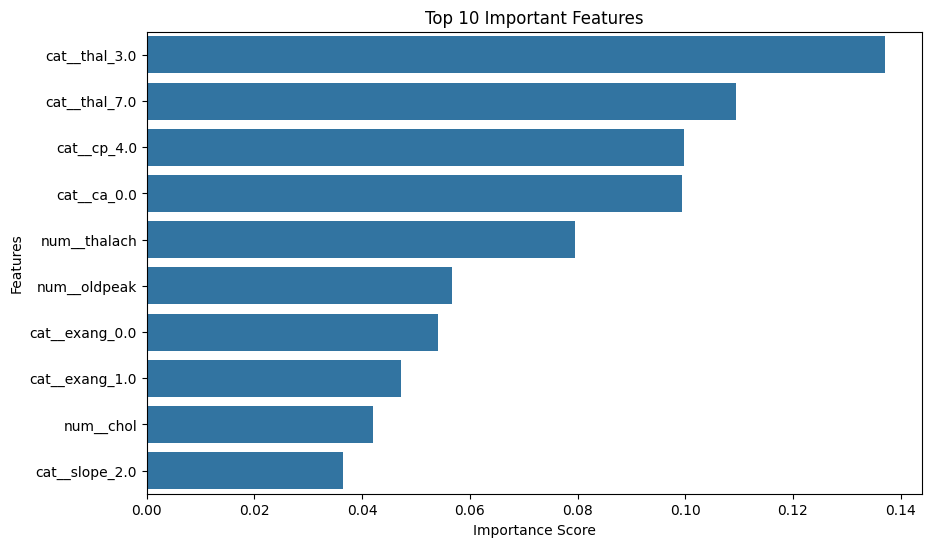

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")

plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [19]:
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Training Accuracy': [
        dt_model.score(X_train, y_train),
        rf_model.score(X_train, y_train)
    ],
    'Testing Accuracy': [
        dt_accuracy,
        rf_accuracy
    ]
})

print(comparison)

           Model  Training Accuracy  Testing Accuracy
0  Decision Tree           0.880165          0.786885
1  Random Forest           0.892562          0.836066


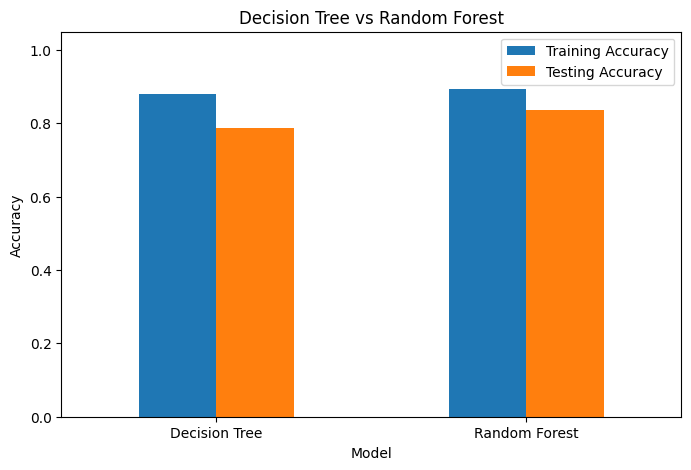

In [20]:
comparison.set_index('Model').plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Decision Tree vs Random Forest")

plt.ylabel("Accuracy")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.show()